# 07 · Regression: how much will the customer spend in the next 6 months?

**Business question:** *how much is each customer worth over the next 6 months?* That's the input for CAC caps, account prioritisation, and the value side of retention targeting.
`y_ltv = 30% × y_spend`. A constant multiplier changes no ranking metric, so we model `y_spend` and convert at the end.

### Why this target is hard
From notebooks 02–03: **about 30–55% of customers spend £0** (by fold), and among buyers spend is roughly **log-normal** with a long tail (a few wholesalers spend £50k+).
So the target is **zero-inflated and heavy-tailed**. Each modelling approach handles that differently:

| Approach | How it handles zeros + tail | Assumption / weakness |
|---|---|---|
| **Plain regression on £ (L2 loss)** | doesn't: squared error is dominated by the few biggest customers | the mean of a skewed target is driven by outliers |
| **Regression on log1p(£)** | log compresses the tail; zeros become 0 | predicts the *median*, not the mean, so totals are too low (back-transform bias) |
| **Tweedie loss** | a distribution with a point mass at 0 plus a skewed positive part (insurance claims) | one model must learn both "whether" and "how much"; a power parameter to choose |
| **Two-part (hurdle)** | P(buy) × E[spend \| buy], each part modelled separately | errors of the two parts multiply; two models to maintain |

### Metrics (from notebook 03)
- **Lead (ranking):** Spearman, normalised Gini, top-10% capture. Who's worth more?
- **Level:** total % error. Does the predicted *sum* match? (budgets, forecasts)
- **Context only:** MAE, RMSE. MAE rewards predicting £0 (notebook 03); RMSE is dominated by the tail.
- **Bar to beat:** "next 6 months = last 6 months" (`spend_180d`).

### 🧠 Predict first
1. Which approach will **rank** customers best? Will any of them clearly beat "last 6 months"?
2. A model trained on log(spend) predicts exp(prediction). Will its **total** be too high or too low? Why?
3. Will ML improve the **top-10% capture** (finding the biggest spenders) or the ordering **further down** the list?

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

sys.path.insert(0, str(Path.cwd().parent))
from src.clean import CLEAN_PARQUET
from src.split import TRAIN_CUTOFFS, MARGIN, time_folds, monthly_cutoffs
from src.preprocess import MODEL_INPUTS
from src.evaluate import regression_metrics, decile_table
from src.models import (make_logreg, make_lgbm_regressor, make_lgbm_log, make_lgbm_tweedie, make_ridge_log,
                        run_folds, run_hurdle)

pd.set_option("display.width", 170)
warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
np.random.seed(SEED)

table = pd.read_parquet(Path(CLEAN_PARQUET).parent / "features.parquet")
FOLDS = time_folds(monthly_cutoffs("2010-09", "2010-12"))
print("Share of £0 spend per validation fold:",
      {v.strftime("%b"): round((table.loc[table["cutoff"] == v, "y_spend"] == 0).mean(), 2) for _, v in FOLDS})

Share of £0 spend per validation fold: {'Sep': np.float64(0.36), 'Oct': np.float64(0.4), 'Nov': np.float64(0.47), 'Dec': np.float64(0.54)}


## 1. Fit every approach on the four time folds

In [2]:
naive = pd.concat([table.loc[table["cutoff"] == v, ["Customer ID", "y_spend", "spend_180d"]]
                   .rename(columns={"y_spend": "y", "spend_180d": "pred"}).assign(fold=v.strftime("%b"), cutoff=v) for _, v in FOLDS])

preds = {
    "naive (last 6m)": naive,
    "LightGBM, L2 on £": run_folds(table, make_lgbm_regressor, "y_spend", FOLDS),
    "LightGBM on log1p, naive back-transform": run_folds(table, lambda: make_lgbm_log(smearing=False), "y_spend", FOLDS),
    "LightGBM on log1p, smearing (all rows)": run_folds(table, make_lgbm_log, "y_spend", FOLDS),
    "Ridge on log1p (clipped inputs)": run_folds(table, lambda: make_ridge_log(smearing=False), "y_spend", FOLDS),
    "LightGBM Tweedie (p=1.5)": run_folds(table, make_lgbm_tweedie, "y_spend", FOLDS),
}
hurdle = run_hurdle(table, FOLDS, make_logreg, make_lgbm_log)  # P(buy): logistic regression (06); spend|buy: LightGBM-log on buyers
preds["Two-part: P(buy) × spend|buy"] = hurdle


def metric_table(preds: dict, metric: str) -> pd.DataFrame:
    t = pd.DataFrame({k: {f: regression_metrics(d["y"], d["pred"])[metric] for f, d in p.groupby("fold", sort=False)}
                      for k, p in preds.items()}).T
    return t.assign(mean=t.mean(axis=1))


spearman, gini, top10, total = (metric_table(preds, m) for m in ["spearman", "gini", "top10_capture", "total_pct_error"])
print("Spearman"); display(spearman.round(3))
print("Normalised Gini"); display(gini.round(3))
print("Top-10% capture"); display(top10.round(3))

Spearman


,Sep,Oct,Nov,Dec,mean
naive (last 6m),0.525,0.518,0.523,0.536,0.525
"LightGBM, L2 on £",0.482,0.474,0.496,0.543,0.499
"LightGBM on log1p, naive back-transform",0.526,0.532,0.539,0.565,0.541
"LightGBM on log1p, smearing (all rows)",0.526,0.532,0.539,0.565,0.541
Ridge on log1p (clipped inputs),0.544,0.546,0.548,0.559,0.549
LightGBM Tweedie (p=1.5),0.523,0.512,0.518,0.545,0.524
Two-part: P(buy) × spend|buy,0.547,0.533,0.536,0.560,0.544


Normalised Gini


,Sep,Oct,Nov,Dec,mean
naive (last 6m),0.793,0.794,0.804,0.829,0.805
"LightGBM, L2 on £",0.768,0.738,0.753,0.827,0.771
"LightGBM on log1p, naive back-transform",0.787,0.778,0.800,0.822,0.797
"LightGBM on log1p, smearing (all rows)",0.787,0.778,0.800,0.822,0.797
Ridge on log1p (clipped inputs),0.764,0.763,0.767,0.787,0.770
LightGBM Tweedie (p=1.5),0.801,0.800,0.810,0.842,0.813
Two-part: P(buy) × spend|buy,0.806,0.795,0.815,0.847,0.816


Top-10% capture


,Sep,Oct,Nov,Dec,mean
naive (last 6m),0.545,0.565,0.579,0.615,0.576
"LightGBM, L2 on £",0.517,0.529,0.544,0.599,0.547
"LightGBM on log1p, naive back-transform",0.521,0.532,0.559,0.599,0.553
"LightGBM on log1p, smearing (all rows)",0.521,0.532,0.559,0.599,0.553
Ridge on log1p (clipped inputs),0.500,0.513,0.527,0.525,0.516
LightGBM Tweedie (p=1.5),0.546,0.541,0.559,0.616,0.566
Two-part: P(buy) × spend|buy,0.545,0.530,0.565,0.615,0.564


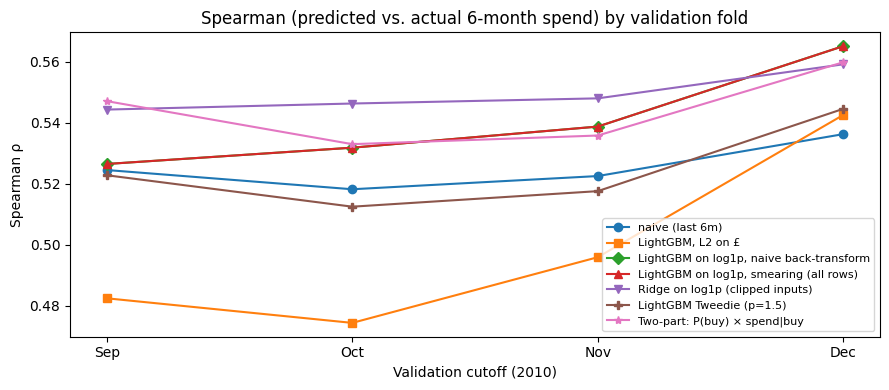

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
for (name, row), m in zip(spearman.drop(columns="mean").iterrows(), "osD^vP*"):
    ax.plot(row.index, row.values, marker=m, label=name)
ax.set_title("Spearman (predicted vs. actual 6-month spend) by validation fold")
ax.set_xlabel("Validation cutoff (2010)")
ax.set_ylabel("Spearman ρ")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**Takeaways on ranking:**
- **Plain L2 regression on £ ranks worst**: below the naive baseline on Gini in every fold and on Spearman in 3 of 4. Squared error lets a handful of wholesalers dictate the fit, so the model spends its capacity on the tail and orders everyone else poorly.
- **The two-part model has the best mean Gini, and the best Spearman among models whose £ level is usable.** It beats the naive baseline on both in every fold.
  Ridge-on-log has the highest Spearman but the lowest Gini (it orders the bulk well and the valuable top badly), and its totals are absurd (section 3).
- **Top-10% capture doesn't improve on the naive rule** (ties in Sep and Dec, losses in Oct and Nov of up to 3.5 points). The biggest future spenders are *already* the biggest recent spenders, and "last 6 months" finds them.
  **The models' gain is in ordering the middle and bottom of the list**, e.g. dormant customers who come back (notebook 03's blind spot). Section 4 shows it in the decile table.
- **The gains are small** (about +0.02 Spearman). For spend, history is a strong predictor and hard to beat, which is a common, honest outcome for LTV models.

### Is the two-part gain real? Paired bootstrap on December

In [4]:
def paired_diff(a: pd.DataFrame, b: pd.DataFrame, fn, n_boot: int = 500) -> tuple:
    a, b = a.sort_values("Customer ID"), b.sort_values("Customer ID")
    y, pa, pb = a["y"].values, a["pred"].values, b["pred"].values
    rng = np.random.default_rng(SEED)
    diffs = [fn(y[i], pa[i]) - fn(y[i], pb[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n_boot))]
    return fn(y, pa) - fn(y, pb), *np.quantile(diffs, [0.025, 0.975])


rho = lambda y, p: spearmanr(y, p).correlation
gin = lambda y, p: regression_metrics(y, p)["gini"]
dec = {k: p[p["fold"] == "Dec"] for k, p in preds.items()}
for name, fn in [("Spearman", rho), ("Gini", gin)]:
    for other in ["naive (last 6m)", "LightGBM Tweedie (p=1.5)"]:
        d, lo, hi = paired_diff(dec["Two-part: P(buy) × spend|buy"], dec[other], fn)
        print(f"Dec {name:<8}: two-part − {other:<24} = {d:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]")

Dec Spearman: two-part − naive (last 6m)          = +0.0236  95% CI [+0.0127, +0.0345]


Dec Spearman: two-part − LightGBM Tweedie (p=1.5) = +0.0153  95% CI [+0.0099, +0.0212]


Dec Gini    : two-part − naive (last 6m)          = +0.0182  95% CI [+0.0102, +0.0273]


Dec Gini    : two-part − LightGBM Tweedie (p=1.5) = +0.0055  95% CI [+0.0017, +0.0093]


**Takeaway:** against the naive baseline, the two-part model's December gain has a CI excluding zero on both Spearman and Gini. It's small but real.
Against Tweedie, the CIs also exclude zero, but the Gini gain is tiny (+0.006), and Tweedie is one model instead of two. Treat them as **close competitors**; notebook 08 tunes the components before notebook 12's final call.

## 2. The back-transform bias: why log models get the total wrong
A model trained on log(spend) predicts the **average of log(spend)**. Turning that back with exp() gives the **median**, not the mean, and for a right-skewed target the median is far below the mean.
**Duan's smearing** fixes it by multiplying by the average of exp(residual) from training:

In [5]:
from src.models import LogTargetRegressor
train_rows = table[table["cutoff"].isin(TRAIN_CUTOFFS)]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    smear_all = make_lgbm_log().fit(train_rows[MODEL_INPUTS], train_rows["y_spend"]).smear_
    buyers = train_rows[train_rows["y_spend"] > 0]
    smear_buyers = make_lgbm_log().fit(buyers[MODEL_INPUTS], buyers["y_spend"]).smear_
print(f"Smearing factor fit on ALL rows (incl. £0): {smear_all:.2f}   |   fit on BUYERS only: {smear_buyers:.2f}")

level = total.loc[["LightGBM on log1p, naive back-transform", "LightGBM on log1p, smearing (all rows)",
                   "Two-part: P(buy) × spend|buy", "LightGBM Tweedie (p=1.5)", "naive (last 6m)"]]
level.round(2)

Smearing factor fit on ALL rows (incl. £0): 6.03   |   fit on BUYERS only: 1.33


,Sep,Oct,Nov,Dec,mean
"LightGBM on log1p, naive back-transform",-0.61,-0.50,-0.33,0.20,-0.31
"LightGBM on log1p, smearing (all rows)",1.09,1.83,2.94,6.27,3.03
Two-part: P(buy) × spend|buy,0.10,0.26,0.67,1.43,0.62
LightGBM Tweedie (p=1.5),0.02,0.21,0.55,1.36,0.53
naive (last 6m),-0.00,0.14,0.43,0.82,0.34


**Takeaways:**
- **Naive back-transform** (exp of the predicted log) predicts the median, so totals are far too low in Sep–Nov (−33% to −61%).
- **Smearing over all rows is *worse*:** the factor is about **6**. Why? Smearing assumes every customer's residual comes from the **same** distribution. With zero-inflation, residuals are bimodal:
  non-buyers sit far *below* the prediction, buyers far *above*. The average exp(residual) is dominated by the buyers, and multiplying *everyone* by 6 inflates totals several-fold.
- **Smearing on buyers only** gives about 1.3, a sensible correction. This is a concrete argument for the **two-part model**: separate "whether" from "how much",
  and the log-scale correction becomes valid for the "how much" part.
- In December the naive back-transform's total looks *good* (+20%), but only because two errors cancel: the median bias (too low) and the season shift (too high). **A right answer for the wrong reason doesn't transfer.**

## 3. The level problem: everyone over-predicts later folds

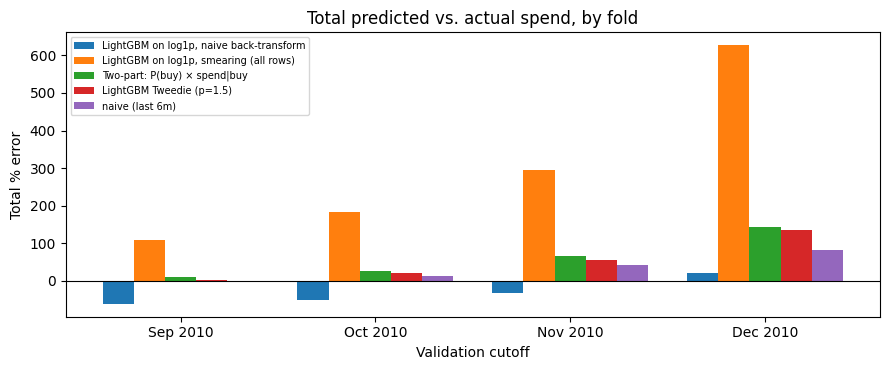

Ridge on log1p total % error by fold: {'Sep': '+193523%', 'Oct': '+33589%', 'Nov': '+22590%', 'Dec': '+11985%', 'mean': '+65422%'}


In [6]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(FOLDS))
for i, (name, row) in enumerate(level.iterrows()):
    ax.bar(x + (i - 2) * 0.16, row[[v.strftime("%b") for _, v in FOLDS]] * 100, width=0.16, label=name)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x, [v.strftime("%b %Y") for _, v in FOLDS])
ax.set_title("Total predicted vs. actual spend, by fold")
ax.set_xlabel("Validation cutoff")
ax.set_ylabel("Total % error")
ax.legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

ridge_tot = total.loc["Ridge on log1p (clipped inputs)"]
print("Ridge on log1p total % error by fold:", {k: f"{v:+.0%}" for k, v in ridge_tot.items()})

**Takeaways:**
- **Every model's total error grows from September to December**, the same pattern as the naive baseline in notebook 03. Models trained on spring/summer cutoffs learned spend levels from windows containing Christmas.
- **Ridge on log1p ranks well but its level is unusable:** a few customers get absurd predictions. A linear model on log scale extrapolates, and exp() turns a moderately large log prediction into an enormous £ value.
  Clipping the inputs helps the ranking but doesn't make its £ trustworthy. **Log-linear models: fine for ranking, dangerous for totals.**

### Decomposing the two-part model's level error (December)

In [7]:
d = hurdle[hurdle["fold"] == "Dec"]
is_buyer = d["y"] > 0
decomp = pd.Series({
    "predicted buyers (Σ P(buy)) ÷ actual buyers": d["p_buy"].sum() / is_buyer.sum(),
    "mean predicted spend|buy ÷ actual spend per buyer (actual buyers)": d.loc[is_buyer, "spend_if_buy"].mean() / d.loc[is_buyer, "y"].mean(),
    "total predicted ÷ total actual": d["pred"].sum() / d["y"].sum(),
})
decomp.round(2).to_frame("ratio")

,ratio
predicted buyers (Σ P(buy)) ÷ actual buyers,1.64
mean predicted spend|buy ÷ actual spend per buyer (actual buyers),1.89
total predicted ÷ total actual,2.43


**Takeaway:** the two-part model over-predicts December's total because **both** parts carry the season. It expects too many buyers (06's calibration problem) **and** too much per buyer:
off-season buyers spend less (notebook 03's buyer-spend histogram shifted left). Fixing only P(buy) with a prior shift won't be enough.
At deployment the level needs a **seasonal adjustment for both parts**, estimated from the same season a year earlier (notebook 12).
**Rule for using this model:** *trust its ranking; calibrate its total separately.*

## 4. Where does the model add value? Decile view (December)

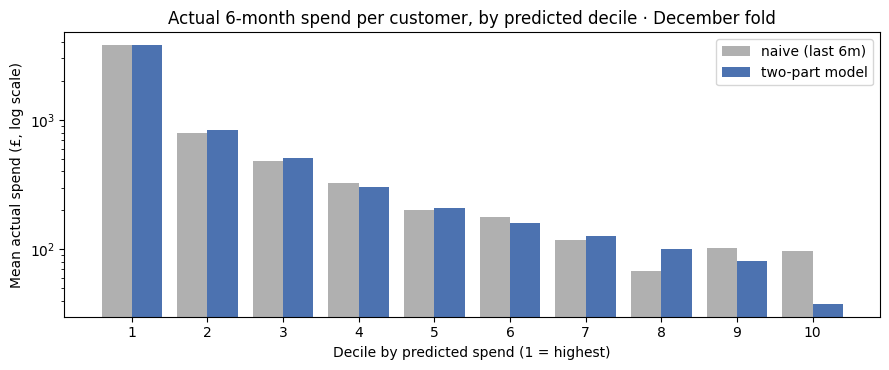

,naive actual £,model actual £,naive share,model share
decile,,,,
1,3773.91,3776.91,0.62,0.62
2,797.50,833.83,0.13,0.14
3,481.11,509.89,0.08,0.08
4,323.76,302.91,0.05,0.05
5,200.36,210.73,0.03,0.03
6,178.74,160.39,0.03,0.03
7,118.04,126.77,0.02,0.02
8,67.88,100.34,0.01,0.02
9,101.94,80.86,0.02,0.01


In [8]:
dt_model = decile_table(dec["Two-part: P(buy) × spend|buy"]["y"], dec["Two-part: P(buy) × spend|buy"]["pred"])
dt_naive = decile_table(dec["naive (last 6m)"]["y"], dec["naive (last 6m)"]["pred"])

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(1, 11)
ax.bar(x - 0.2, dt_naive["mean_actual"], width=0.4, label="naive (last 6m)", color="#B0B0B0")
ax.bar(x + 0.2, dt_model["mean_actual"], width=0.4, label="two-part model", color="#4C72B0")
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_title("Actual 6-month spend per customer, by predicted decile · December fold")
ax.set_xlabel("Decile by predicted spend (1 = highest)")
ax.set_ylabel("Mean actual spend (£, log scale)")
ax.legend()
plt.tight_layout()
plt.show()

pd.DataFrame({"naive actual £": dt_naive["mean_actual"], "model actual £": dt_model["mean_actual"],
              "naive share": dt_naive["share_of_actual"], "model share": dt_model["share_of_actual"]}).round(2)

**Takeaway:** decile 1 is about the same for both: the top spenders are easy. The difference is at the **bottom**. The naive rule's last two deciles (customers with £0 in the last 6 months)
still contain returning customers, while the model's bottom deciles are cleaner and decline steadily, because it uses longer history (spend per month, tenure, typical gap) to tell *dormant-but-coming-back* from *gone*.

**Business translation:** if the decision is *"who are our top 10%?"*, the naive rule is nearly as good. If the decision is *"who in the long tail is worth a reactivation offer, and who can we stop spending on?"*,
the model is better. That's where it pays for itself.

## 5. Decision & LTV

In [9]:
summary = pd.DataFrame({"mean Spearman": spearman["mean"], "mean Gini": gini["mean"], "mean top-10% capture": top10["mean"],
                        "Dec total % error": total["Dec"]})
display(summary.round(3))

ltv = dec["Two-part: P(buy) × spend|buy"].assign(pred_ltv=lambda d: MARGIN * d["pred"], actual_ltv=lambda d: MARGIN * d["y"])
print(f"December: predicted 6-month LTV per customer (mean) £{ltv['pred_ltv'].mean():,.0f} vs. actual £{ltv['actual_ltv'].mean():,.0f} "
      f"→ ranking usable, level must be recalibrated")

hurdle.to_parquet(Path(CLEAN_PARQUET).parent / "val_preds_spend.parquet", index=False)

,mean Spearman,mean Gini,mean top-10% capture,Dec total % error
naive (last 6m),0.525,0.805,0.576,0.818
"LightGBM, L2 on £",0.499,0.771,0.547,1.483
"LightGBM on log1p, naive back-transform",0.541,0.797,0.553,0.205
"LightGBM on log1p, smearing (all rows)",0.541,0.797,0.553,6.269
Ridge on log1p (clipped inputs),0.549,0.770,0.516,119.846
LightGBM Tweedie (p=1.5),0.524,0.813,0.566,1.361
Two-part: P(buy) × spend|buy,0.544,0.816,0.564,1.432


December: predicted 6-month LTV per customer (mean) £449 vs. actual £184 → ranking usable, level must be recalibrated


| Decision | Choice | Alternative not picked & why |
|---|---|---|
| Spend model | **two-part**: logistic P(buy) × LightGBM-on-log1p spend\|buy | Tweedie: close runner-up, simpler (one model); L2 on £: worst ranking; ridge-log: absurd totals |
| Back-transform | smearing **fit on buyers only** (≈ 1.3) | naive exp: predicts the median (−60% totals); smearing on all rows: ≈ 6×, inflates totals |
| What to trust | ranking (Spearman, Gini) | level: over-predicts off-season by about 2×, needs seasonal recalibration |
| LTV | 30% × predicted spend | product-level margins (not in the data) |

**Honest summary for an interviewer:** *"For spend, 'last 6 months' was a strong baseline. A two-part model beat it on rank correlation in every fold, with a significant but small gain,
mostly by sorting the long tail better rather than finding new top spenders. Totals needed separate seasonal calibration."*

### 🧠 Interpret
1. Check your predictions: which approach ranked best, and was the log model's total too high or too low?
2. Explain to a PM, without formulas, why exp(average of log spend) under-estimates average spend. (Hint: what happens to one £50k customer in log space?)
3. Why did smearing over *all* rows give a factor of about 6, and why does the two-part model fix that?
4. The model doesn't improve top-10% capture. Is it still worth deploying? For which business decision, and for which not?
5. **ARQ:** FX volume per user is also zero-inflated and heavy-tailed. Which approach would you start with, and what's the "two parts" story in ARQ terms?